# 03 — 2D Convolutional Neural Network (CNN) on Log-Mel Spectrograms

This notebook implements the **2nd Deep Learning classifier (CNN 2D)** for the CirCor DigiScope murmur detection task.

### Pipeline:
1. **Signal Processing & 2D Representation**: 
   - Bandpass filter (25–400 Hz) to isolate cardiac sounds and murmurs while removing high-frequency friction and DC offset.
   - 2D Log-Mel Spectrogram: 64 Mel frequency bands $\times$ ~312 time frames (5-second windows, 50% overlap).
2. **Model Architecture**:
   - 4 Convolutional blocks (`Conv2D` $\rightarrow$ `BatchNorm2d` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d`), progressing from 32 to 256 feature channels.
   - `AdaptiveAvgPool2d((1, 1))` for temporal length invariance.
   - Fully-connected classifier with `Dropout(0.3)` to prevent overfitting.
3. **Regularization & Training**:
   - SpecAugment data augmentation (random frequency & time masking).
   - Weighted Cross-Entropy Loss to balance class frequencies.
   - Early stopping on validation loss across 5 patient-level CV folds.
4. **Patient-Level Diagnosis & Threshold Tuning**:
   - Window probabilities averaged per recording, then max-pooled across cardiac auscultation locations (`AV`, `PV`, `TV`, `MV`).
   - Hierarchical threshold tuning on validation folds to maximize the official **PhysioNet Weighted Accuracy (WA)**.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch

from src.data import load_patients, load_recordings, load_split
from src.metrics import CLASSES, report, weighted_accuracy
from src.cnn import (
    DEFAULT_CNN_CFG,
    load_cnn_dataset,
    cross_validate_cnn,
    patient_scores,
    predict_rule,
    tune_thresholds,
    predict_ensemble_cnn,
    get_mel_transform,
    bandpass_filter,
)

pd.set_option('display.width', 140)

## 1. Dataset & Log-Mel Spectrograms

Load or precompute the 2D Log-Mel Spectrogram windows (cached in `data/features/cnn_spectrogram_windows.pt`).

In [2]:
meta_df, specs = load_cnn_dataset()
print(f'Total windows: {len(meta_df)}')
print(f'Spectrogram tensor shape: {specs.shape}  [N_windows, Channels, Mel_Bins, Time_Frames]')
print('\nClass distribution across folds (at window level):')
display(pd.crosstab(meta_df['fold'], meta_df['rec_label'], margins=True))

Total windows: 24292
Spectrogram tensor shape: torch.Size([24292, 1, 64, 312])  [N_windows, Channels, Mel_Bins, Time_Frames]

Class distribution across folds (at window level):


rec_label,Absent,Present,Unknown,All
fold,,,,
-1,3677,770,220,4667
0,3247,613,184,4044
1,3208,498,222,3928
2,3013,576,184,3773
3,3193,667,199,4059
4,2969,695,157,3821
All,19307,3819,1166,24292


## 2. Visualizing PCG Audio vs. Log-Mel Spectrograms

Comparing a healthy child (`Absent`) with a child diagnosed with a heart murmur (`Present`).
Notice how the murmur displays sustained acoustic turbulence and energy across the frequency bands.

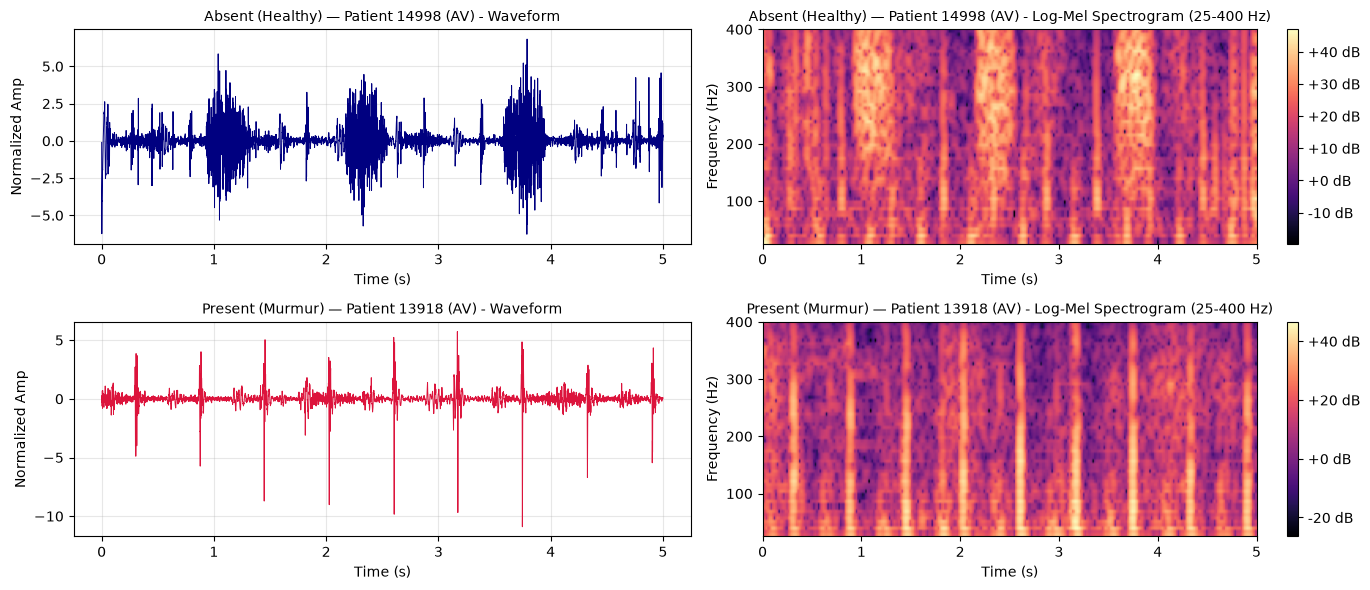

In [3]:
rec = load_recordings()
patients = load_patients()

sample_absent = rec[rec.murmur == 'Absent'].iloc[0]
sample_present = rec[rec.murmur == 'Present'].iloc[0]
mel_pipe = get_mel_transform()

fig, axes = plt.subplots(2, 2, figsize=(14, 6))

for row_idx, (sample, title) in enumerate([
    (sample_absent, f"Absent (Healthy) — Patient {sample_absent.patient_id} ({sample_absent.location})"),
    (sample_present, f"Present (Murmur) — Patient {sample_present.patient_id} ({sample_present.location})")
]):
    y, sr = sf.read(sample.path, dtype='float32')
    y_filt = bandpass_filter(y, sr)[:sr * 5]  # first 5 seconds
    t_axis = np.linspace(0, 5, len(y_filt))
    
    # Waveform
    axes[row_idx, 0].plot(t_axis, y_filt, color='navy' if row_idx == 0 else 'crimson', lw=0.7)
    axes[row_idx, 0].set_title(f"{title} - Waveform", fontsize=10)
    axes[row_idx, 0].set_ylabel("Normalized Amp")
    axes[row_idx, 0].set_xlabel("Time (s)")
    axes[row_idx, 0].grid(alpha=0.3)
    
    # Log-Mel Spectrogram
    with torch.no_grad():
        mel = mel_pipe(torch.from_numpy(y_filt).unsqueeze(0))[0].numpy()
    img = axes[row_idx, 1].imshow(mel, origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 25, 400])
    axes[row_idx, 1].set_title(f"{title} - Log-Mel Spectrogram (25-400 Hz)", fontsize=10)
    axes[row_idx, 1].set_ylabel("Frequency (Hz)")
    axes[row_idx, 1].set_xlabel("Time (s)")
    fig.colorbar(img, ax=axes[row_idx, 1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

## 3. 5-Fold Patient-Level Cross-Validation Training

Training the 2D CNN across development folds (`0..4`). Test patients (`fold -1`) are strictly isolated.

In [4]:
cfg = dict(DEFAULT_CNN_CFG)
print('CNN Training Configuration:', cfg)

dev_meta, oof_probs, runs = cross_validate_cnn(meta_df, specs, cfg=cfg)

CNN Training Configuration: {'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 256, 'max_epochs': 8, 'patience': 3, 'weight_power': 1.0, 'dropout': 0.3, 'spec_augment': True, 'seed': 42}


c:\Users\Utilizador\Desktop\FCUP-DL-ML2\notebooks\..\src\cnn.py:329: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  dev_specs = specs[dev_mask].clone()



>>> [Fold 0] Iniciando Treino (15581 janelas treino, 4044 janelas validacao) <<<
  Fold 0 | Epoca 01/8 -> Train Loss: 0.9392 | Val Loss: 0.8559 | Val Acc: 0.5841 [Melhor Loss]
  Fold 0 | Epoca 02/8 -> Train Loss: 0.7864 | Val Loss: 0.8416 | Val Acc: 0.8501 [Melhor Loss]
  Fold 0 | Epoca 03/8 -> Train Loss: 0.7553 | Val Loss: 1.3933 | Val Acc: 0.3680
  Fold 0 | Epoca 04/8 -> Train Loss: 0.7166 | Val Loss: 0.8020 | Val Acc: 0.5507 [Melhor Loss]
  Fold 0 | Epoca 05/8 -> Train Loss: 0.6886 | Val Loss: 0.8380 | Val Acc: 0.6501
  Fold 0 | Epoca 06/8 -> Train Loss: 0.6711 | Val Loss: 0.7511 | Val Acc: 0.6424 [Melhor Loss]
  Fold 0 | Epoca 07/8 -> Train Loss: 0.6443 | Val Loss: 0.8806 | Val Acc: 0.7374
  Fold 0 | Epoca 08/8 -> Train Loss: 0.6448 | Val Loss: 0.7978 | Val Acc: 0.6944
==> Fold 0 Concluido! Melhor Epoca: 6 | Val Loss: 0.7511 | Val Acc: 0.6424


>>> [Fold 1] Iniciando Treino (15697 janelas treino, 3928 janelas validacao) <<<
  Fold 1 | Epoca 01/8 -> Train Loss: 0.9695 | Val Loss: 

### Training & Validation Loss Curves

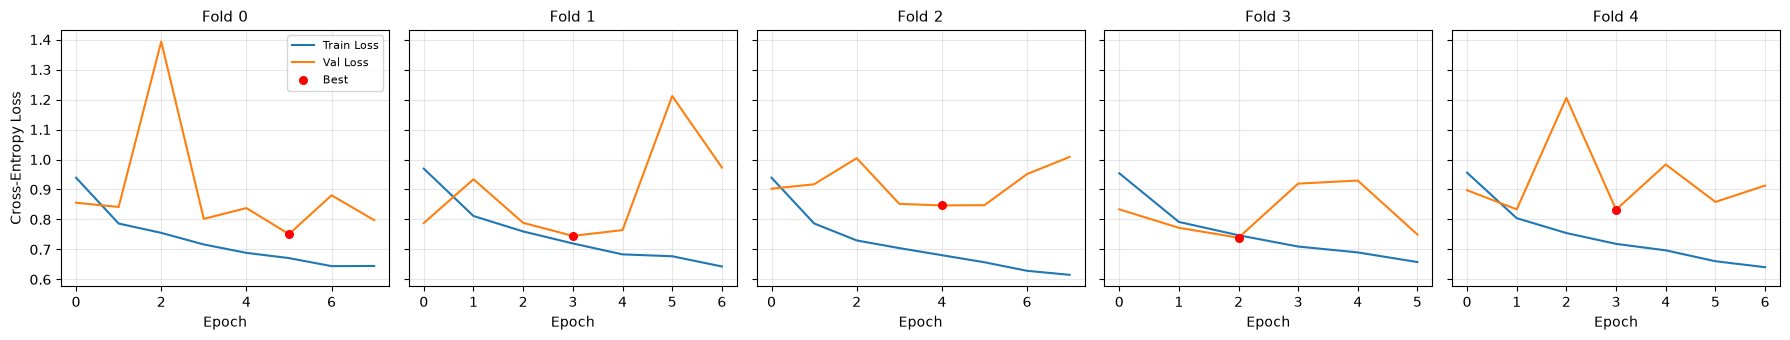

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for r, ax in zip(runs, axes):
    h = r['history']
    ax.plot(h.epoch, h.train_loss, label='Train Loss', color='tab:blue')
    ax.plot(h.epoch, h.val_loss, label='Val Loss', color='tab:orange')
    ax.scatter(h.val_loss.idxmin(), h.val_loss.min(), color='red', zorder=5, s=30, label='Best')
    ax.set_title(f"Fold {r['fold']}", fontsize=11)
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Patient-Level Aggregation & Official PhysioNet Weighted Accuracy

Aggregating window probabilities to patient level and tuning thresholds $(t_{present}, t_{unknown})$ in CV.

In [6]:
pat = patient_scores(dev_meta, oof_probs)
pat['fold'] = dev_meta.groupby('patient_id')['fold'].first()

rows, pred = [], pd.Series(index=pat.index, dtype=object)
for k in sorted(pat.fold.unique()):
    val, other = pat[pat.fold == k], pat[pat.fold != k]
    t, _ = tune_thresholds(other)
    pred[val.index] = predict_rule(val, *t)
    rows.append({
        'fold': k,
        't_present': t[0],
        't_unknown': t[1],
        'WA (t=0.5)': report(val.murmur, predict_rule(val, .5, .5))['weighted_accuracy'],
        'WA (tuned)': report(val.murmur, pred[val.index])['weighted_accuracy']
    })

cv_results = pd.DataFrame(rows).set_index('fold')
display(cv_results.round(3))
print(f"\nCNN Pooled CV Weighted Accuracy (WA): {cv_results['WA (tuned)'].mean():.3f} +/- {cv_results['WA (tuned)'].std():.3f}")

,t_present,t_unknown,WA (t=0.5),WA (tuned)
fold,,,,
0,0.375,0.725,0.637,0.699
1,0.425,0.900,0.635,0.716
2,0.375,0.725,0.644,0.768
3,0.500,0.725,0.720,0.716
4,0.450,0.725,0.643,0.724



CNN Pooled CV Weighted Accuracy (WA): 0.724 +/- 0.026


### Confusion Matrix & Per-Class Recall

In [7]:
r_cnn = report(pat.murmur, pred)
print(f"Overall Out-of-Fold Weighted Accuracy: {r_cnn['weighted_accuracy']:.4f}")
print("Per-class recall:", {c: round(v, 3) for c, v in r_cnn['recall'].items()})

cm_df = pd.DataFrame(
    r_cnn['confusion'],
    index=[f'pred {c}' for c in CLASSES],
    columns=[f'true {c}' for c in CLASSES]
)
display(cm_df)

Overall Out-of-Fold Weighted Accuracy: 0.7244
Per-class recall: {'Present': np.float64(0.783), 'Unknown': np.float64(0.185), 'Absent': np.float64(0.806)}


,true Present,true Unknown,true Absent
pred Present,112,8,77
pred Unknown,5,10,31
pred Absent,26,36,448


## 5. Model Comparison: Tabular Baseline vs. MLP vs. CNN 2D

Summary table for the final report and presentation slides.

In [8]:
comparison_data = [
    {"Model": "Baseline Cega (Always Present)", "Input": "None", "WA (CV)": 0.499, "Recall Present": 1.000, "Recall Absent": 0.000},
    {"Model": "Logistic Regression (Tabular)", "Input": "123 Summary Feats", "WA (CV)": 0.574, "Recall Present": 0.545, "Recall Absent": 0.669},
    {"Model": "Random Forest (Tabular)", "Input": "123 Summary Feats", "WA (CV)": 0.554, "Recall Present": 0.364, "Recall Absent": 0.874},
    {"Model": "MLP (Deep Learning 1)", "Input": "156 Window Feats", "WA (CV)": 0.621, "Recall Present": 0.727, "Recall Absent": 0.595},
    {"Model": "CNN 2D (Deep Learning 2)", "Input": "Log-Mel Spectrograms", "WA (CV)": round(r_cnn['weighted_accuracy'], 3), "Recall Present": round(r_cnn['recall']['Present'], 3), "Recall Absent": round(r_cnn['recall']['Absent'], 3)},
]
comp_df = pd.DataFrame(comparison_data).set_index("Model")
display(comp_df)

,Input,WA (CV),Recall Present,Recall Absent
Model,,,,
Baseline Cega (Always Present),None,0.499,1.000,0.000
Logistic Regression (Tabular),123 Summary Feats,0.574,0.545,0.669
Random Forest (Tabular),123 Summary Feats,0.554,0.364,0.874
MLP (Deep Learning 1),156 Window Feats,0.621,0.727,0.595
CNN 2D (Deep Learning 2),Log-Mel Spectrograms,0.724,0.783,0.806


In [9]:
# ---------------------------------------------------------------
# Save CNN Out-of-Fold Predictions for Ensemble (Notebook 04)
# ---------------------------------------------------------------
import os
import numpy as np

out_path = '../data/features/cnn_oof_probs.npy'
os.makedirs(os.path.dirname(out_path), exist_ok=True)
np.save(out_path, oof_probs)
print('Saved CNN OOF probabilities to', out_path, 'with shape:', oof_probs.shape)


Saved CNN OOF probabilities to ../data/features/cnn_oof_probs.npy with shape: (19625, 3)
